# QDC Fall 2026: 50 ETF EDA
### ReBel Agentic AI Challenge | Team 29
**Objective:** Provide a comprehensive analytical foundation for the Human-in-the-Loop (HITL) investment committee.
1. **Catalog & Characterize:** Define all 50 ETFs across 20 official themes and evaluate their underlying exposures.
2. **Exploratory Data Analysis (EDA):** Quantify 3-year historical returns, annualized volatility, max drawdowns, and cross-asset correlations (all normalized to EUR).
3. **Decay Mechanics:** Analyze the mathematical compounding volatility drag of daily leveraged and inverse products.
4. **Decision-Oriented Taxonomy:** Categorize the 50 instruments into 4 actionable buckets to guide human trade approval during the 5 live competition dates.


## 1. Defining the 50 ETF Universe
Below is the structured breakdown of the 50 instruments from Slides 9 & 10 of the Belfius Challenge Deck.
We categorize them into **9 macroeconomic asset clusters** to reveal their distinct risk-return engines.


In [1]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), '..')) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
os.chdir(project_root)

if project_root not in sys.path:
    sys.path.insert(0, project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.pipeline.etf_universe import ETF_UNIVERSE

# Configure visual style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.figsize'] = (12, 6)

# Build a comprehensive descriptive DataFrame
etf_data = []
for etf in ETF_UNIVERSE:
    if etf.theme in ['Global equity (benchmark)', 'US equity', 'European equity', 'Home market']:
        macro_cat = '1. Developed Core Equities'
    elif etf.theme in ['Size & style factors', 'Income strategies']:
        macro_cat = '2. Factor & Income Equities'
    elif etf.theme in ['Equity / Tech', 'Frontier tech']:
        macro_cat = '3. Technology & Innovation'
    elif etf.theme == 'Emerging markets':
        macro_cat = '4. Emerging Markets'
    elif etf.theme in ['Energy & commodities', 'Energy transition']:
        macro_cat = '5. Energy & Commodities'
    elif etf.theme in ['Industrial & strategic metals', 'Precious metals']:
        macro_cat = '6. Metals & Mining'
    elif etf.theme in ['Fixed income / Bonds', 'Money market (cash)']:
        macro_cat = '7. Fixed Income & Cash'
    elif etf.theme == 'Defensive sector':
        macro_cat = '8. Defensive Equities'
    elif etf.theme == 'Digital assets':
        macro_cat = '9. Digital Assets'
    elif etf.theme == 'Leveraged & inverse':
        macro_cat = '10. Leveraged & Inverse'
    else:
        macro_cat = 'Other'

    etf_data.append({
        'ID': etf.id,
        'Ticker': etf.ticker,
        'Name': etf.full_name,
        'Theme': etf.theme,
        'Macro Category': macro_cat,
        'ISIN': etf.isin,
        'Base Ccy': etf.currency,
        'Leverage': f'{etf.leverage:+.0f}x' if etf.is_leveraged_or_short else '1.0x',
        'Is Leveraged/Short': etf.is_leveraged_or_short
    })

df_etfs = pd.DataFrame(etf_data)
print(f'Total instruments registered: {len(df_etfs)}')
#df_etfs.head(10)
df_etfs


Total instruments registered: 50


,ID,Ticker,Name,Theme,Macro Category,ISIN,Base Ccy,Leverage,Is Leveraged/Short
0,1,WORLD,iShares Core MSCI World UCITS ETF,Global equity (benchmark),1. Developed Core Equities,IE00B4L5Y983,EUR,1.0x,False
1,2,S&P 500,iShares Core S&P 500 UCITS ETF,US equity,1. Developed Core Equities,IE00B5BMR087,EUR,1.0x,False
2,3,EUROPE 600,Amundi Core Stoxx Europe 600 UCITS ETF,European equity,1. Developed Core Equities,LU0908500753,EUR,1.0x,False
3,4,EURO STOXX 50,iShares Core EURO STOXX 50 UCITS ETF,European equity,1. Developed Core Equities,IE00B53L3W79,EUR,1.0x,False
4,5,IBEX 35,Amundi IBEX 35 UCITS ETF,European equity,1. Developed Core Equities,FR0010655746,EUR,1.0x,False
5,6,BEL 20,Amundi BEL 20 UCITS ETF,Home market,1. Developed Core Equities,FR0000021842,EUR,1.0x,False
6,7,WORLD SMALL CAP,iShares MSCI World Small Cap UCITS ETF,Size & style factors,2. Factor & Income Equities,IE00BF4RFH31,EUR,1.0x,False
7,8,WORLD MIN VOL,iShares Edge MSCI World Minimum Volatility,Size & style factors,2. Factor & Income Equities,IE00B8FHGS14,USD,1.0x,False
8,9,DIVIDEND LEADERS,VanEck Developed Markets Dividend Leaders,Size & style factors,2. Factor & Income Equities,NL0011683594,EUR,1.0x,False
9,10,NASDAQ INCOME,JPMorgan Nasdaq Equity Premium Income,Income strategies,2. Factor & Income Equities,IE000U9J8HX9,EUR,1.0x,False


## 2. Ingesting Normalized Historical EUR Data & Computing Quant Metrics
We load the 3-year historical daily EUR prices generated by our data pipeline (`data/etf_prices_eur.parquet`).
We compute:
* **Annualized Return:** Compound annual growth rate over the 3-year history.
* **Annualized Volatility:** Standard deviation of daily returns scaled by $\sqrt{252}$.
* **Sharpe Ratio:** Assuming an ECB risk-free rate of $3.0\%$.
* **Maximum Drawdown:** The largest peak-to-trough decline over the period.


In [2]:
# Load historical EUR prices
prices = pd.read_parquet('data/etf_prices_eur.parquet')
daily_returns = prices.pct_change().dropna(how='all')

# Tinh toan loi nhuan va do bien dong chuan hoa cho tung ETF
# (Dung gia hop le dau tien cua tung ETF de khong bi loi NaN cho cac ETF thanh lap sau Nov 2023)
ann_factor = 252
first_valid_prices = prices.apply(lambda s: s.dropna().iloc[0])
last_valid_prices = prices.apply(lambda s: s.dropna().iloc[-1])
trading_days_per_etf = prices.apply(lambda s: len(s.dropna()) - 1)

ann_return = (last_valid_prices / first_valid_prices) ** (ann_factor / trading_days_per_etf) - 1.0
ann_vol = daily_returns.std() * np.sqrt(ann_factor)

rf_rate = 0.03 # Lai suat phi rui ro tham chieu (ECB ~3.0%)
sharpe_ratio = (ann_return - rf_rate) / ann_vol

# Maximum Drawdown calculation
cum_max = prices.cummax()
drawdowns = (prices - cum_max) / cum_max
max_dd = drawdowns.min()

metrics_df = pd.DataFrame({
    'Annualized Return': ann_return,
    'Annualized Volatility': ann_vol,
    'Sharpe Ratio': sharpe_ratio,
    'Max Drawdown': max_dd,
    'Observed Days': trading_days_per_etf
})

summary_table = df_etfs.merge(metrics_df, left_on='Ticker', right_index=True)
summary_table['Ann. Return %'] = (summary_table['Annualized Return'] * 100).round(1)
summary_table['Ann. Vol %'] = (summary_table['Annualized Volatility'] * 100).round(1)
summary_table['Max DD %'] = (summary_table['Max Drawdown'] * 100).round(1)
summary_table['Sharpe'] = summary_table['Sharpe Ratio'].round(2)

print(f'Tong so ETF duoc danh gia: {len(summary_table)}')
print(f'So ETF bi NaN Sharpe: {summary_table["Sharpe"].isna().sum()}')
summary_table.sort_values(by='Sharpe', ascending=False)[['ID', 'Ticker', 'Macro Category', 'Ann. Return %', 'Ann. Vol %', 'Max DD %', 'Sharpe', 'Observed Days']]


Tong so ETF duoc danh gia: 50
So ETF bi NaN Sharpe: 0


,ID,Ticker,Macro Category,Ann. Return %,Ann. Vol %,Max DD %,Sharpe,Observed Days
4,5,IBEX 35,1. Developed Core Equities,30.0,16.3,-12.6,1.66,675
8,9,DIVIDEND LEADERS,2. Factor & Income Equities,18.6,11.4,-15.3,1.36,779
29,30,HYDROGEN,5. Energy & Commodities,25.2,17.1,-15.8,1.30,779
5,6,BEL 20,1. Developed Core Equities,20.7,13.6,-14.0,1.30,779
0,1,WORLD,1. Developed Core Equities,18.3,13.0,-21.6,1.18,779
1,2,S&P 500,1. Developed Core Equities,18.9,14.1,-23.3,1.13,779
15,16,SPACE,3. Technology & Innovation,46.2,38.7,-52.1,1.12,779
11,12,SEMIS,3. Technology & Innovation,42.1,35.3,-39.3,1.11,779
40,41,DEFENSE,8. Defensive Equities,28.3,23.6,-25.6,1.07,779
33,34,GOLD MINERS,6. Metals & Mining,43.0,39.6,-36.0,1.01,779


## 3. Exploratory Data Analysis (EDA)

### 3.1 Risk vs. Return Landscape
Visualizing where the 50 ETFs sit on the Efficient Frontier in EUR terms. Notice the extreme dispersion of high-beta and leveraged assets.


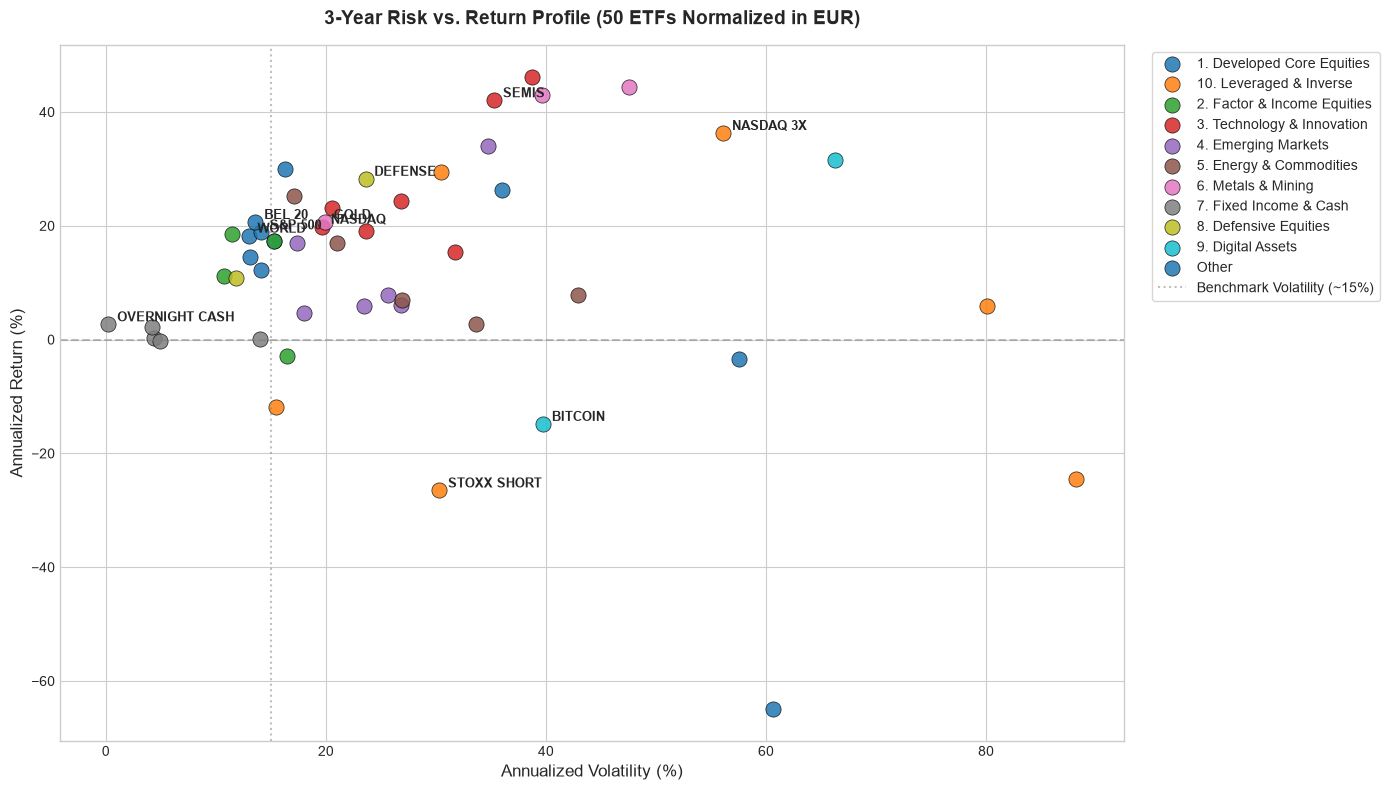

In [3]:
plt.figure(figsize=(14, 8))
categories = summary_table["Macro Category"].unique()
palette = sns.color_palette("tab10", len(categories))

for i, cat in enumerate(sorted(categories)):
    subset = summary_table[summary_table["Macro Category"] == cat]
    plt.scatter(
        subset["Annualized Volatility"] * 100,
        subset["Annualized Return"] * 100,
        s=120,
        label=cat,
        alpha=0.85,
        edgecolors="black",
        linewidths=0.5
    )
    # Label key assets
    for _, row in subset.iterrows():
        if row["Ticker"] in ["WORLD", "S&P 500", "BEL 20", "NASDAQ", "SEMIS", "GOLD", "DEFENSE", "BITCOIN", "NASDAQ 3X", "STOXX SHORT", "OVERNIGHT CASH"]:
            plt.annotate(
                row["Ticker"],
                (row["Annualized Volatility"] * 100 + 0.8, row["Annualized Return"] * 100 + 0.5),
                fontsize=9,
                fontweight="bold"
            )

plt.axhline(0, color="grey", linestyle="--", alpha=0.5)
plt.axvline(15, color="grey", linestyle=":", alpha=0.5, label="Benchmark Volatility (~15%)")
plt.title("3-Year Risk vs. Return Profile (50 ETFs Normalized in EUR)", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Annualized Volatility (%)", fontsize=12)
plt.ylabel("Annualized Return (%)", fontsize=12)
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True)
plt.tight_layout()
plt.show()


### 3.2 Maximum Drawdown Comparison
In the QDC, capital preservation is paramount. The chart below ranks the most severe historical drawdowns across the universe. Note that daily leveraged instruments (`PALLADIUM LVG`, `COPPER LVG`, `STOXX SHORT`) suffered catastrophic $>50\%$ peak-to-trough drawdowns.


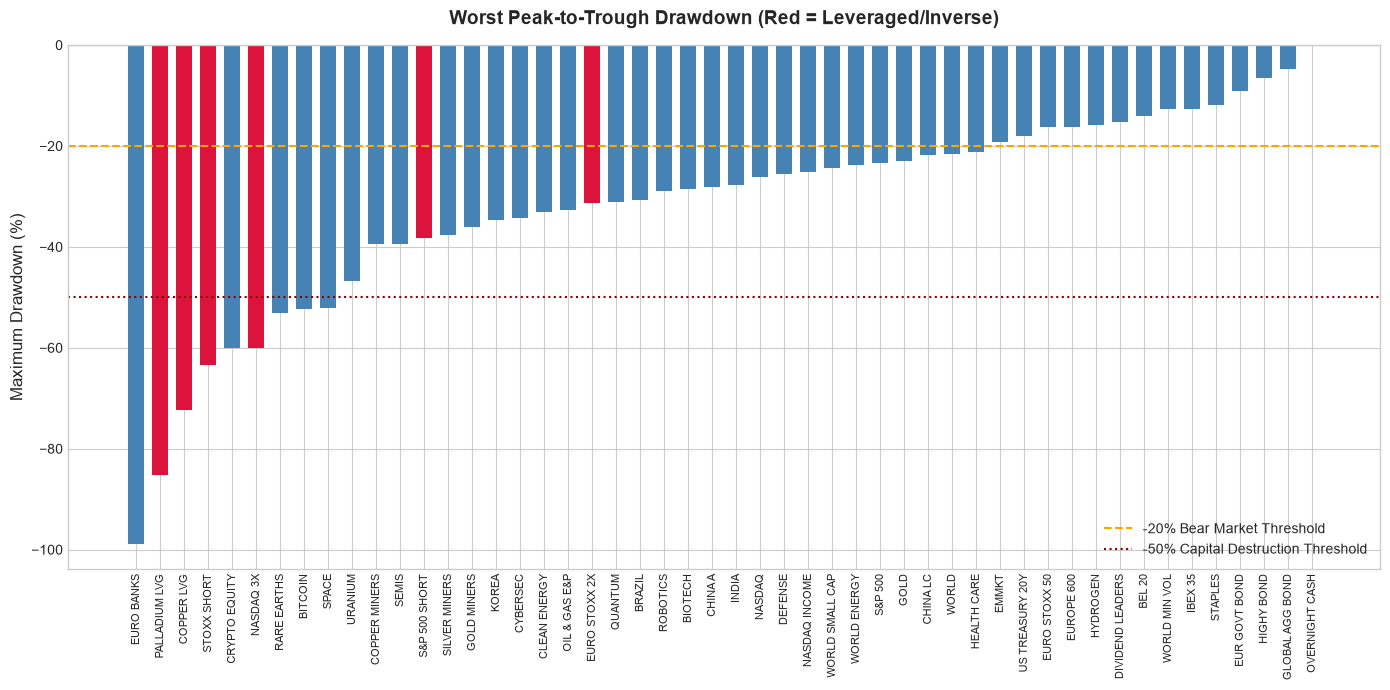

In [4]:
plt.figure(figsize=(14, 7))
sorted_dd = summary_table.sort_values(by="Max Drawdown")
colors = ["crimson" if is_lev else "steelblue" for is_lev in sorted_dd["Is Leveraged/Short"]]

bars = plt.bar(sorted_dd["Ticker"], sorted_dd["Max Drawdown"] * 100, color=colors, width=0.7)
plt.xticks(rotation=90, fontsize=8)
plt.title("Worst Peak-to-Trough Drawdown (Red = Leveraged/Inverse)", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Maximum Drawdown (%)", fontsize=12)
plt.axhline(-20, color="orange", linestyle="--", label="-20% Bear Market Threshold")
plt.axhline(-50, color="darkred", linestyle=":", label="-50% Capital Destruction Threshold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


### 3.3 Cross-Asset Correlation Heatmap
To construct a resilient portfolio, the trader must understand which assets serve as true hedges against equity downturns.


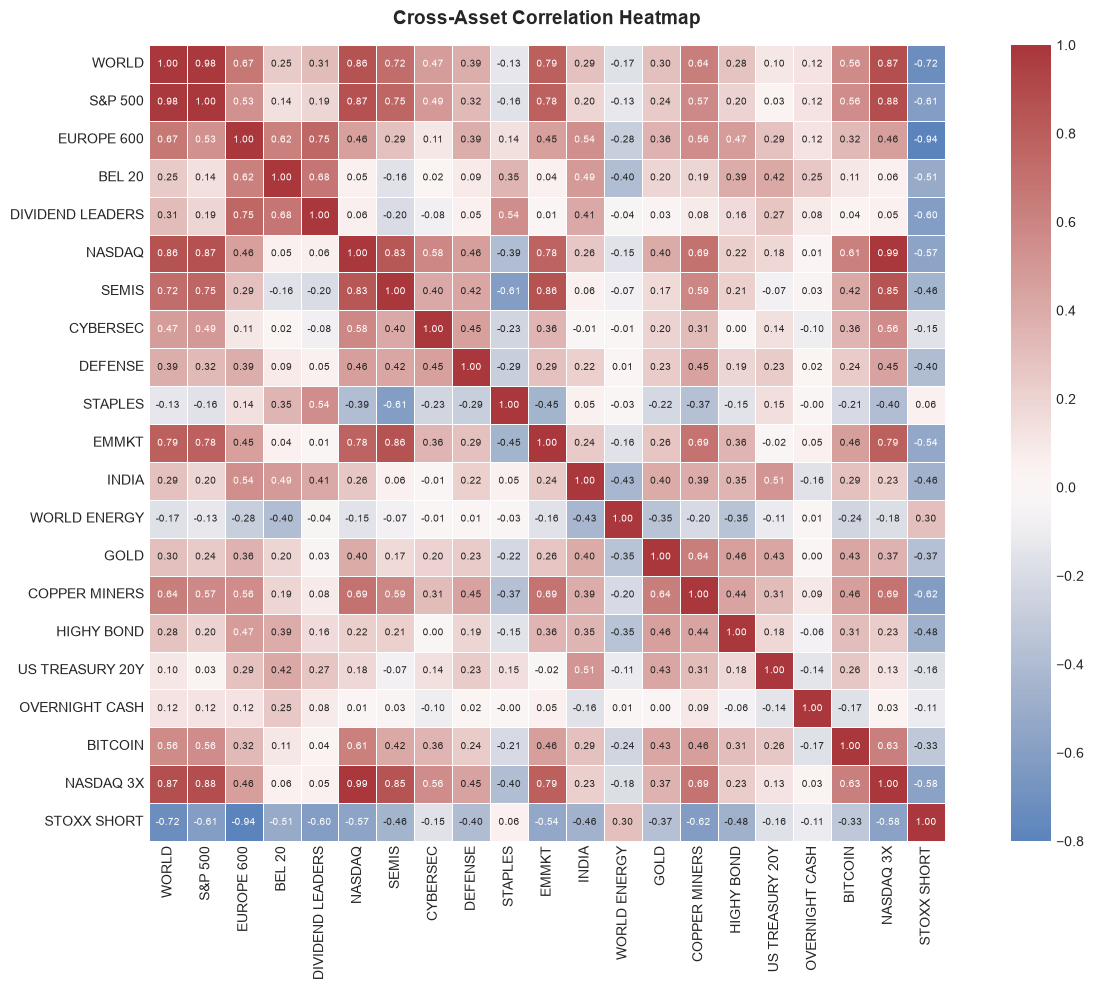

In [5]:
# Load correlation matrix
corr_matrix = pd.read_csv('data/etf_correlation_matrix.csv', index_col=0)

# Select representative assets across themes for clean visualization
key_assets = [
    'WORLD', 'S&P 500', 'EUROPE 600', 'BEL 20', 'DIVIDEND LEADERS',
    'NASDAQ', 'SEMIS', 'CYBERSEC', 'DEFENSE', 'STAPLES',
    'EMMKT', 'INDIA', 'WORLD ENERGY', 'GOLD', 'COPPER MINERS',
    'HIGHY BOND', 'US TREASURY 20Y', 'OVERNIGHT CASH', 'BITCOIN',
    'NASDAQ 3X', 'STOXX SHORT'
]
sub_corr = corr_matrix.loc[key_assets, key_assets]

plt.figure(figsize=(14, 10))
sns.heatmap(sub_corr, cmap='vlag', center=0, vmin=-0.8, vmax=1.0, annot=True, fmt='.2f', annot_kws={'size': 7.5}, square=True, linewidths=0.5)
plt.title('Cross-Asset Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()


### 3.4 The Leveraged ETF Compounding Drag (Beta Slippage)
A critical insight for the QDC Investment Committee: **Daily leveraged ETFs do not deliver multiple long-term returns in volatile or sideways markets due to path dependency ($100 \times 1.10 \times 0.90 = 99$).**
Below we compare the normalized price paths of `NASDAQ` vs `NASDAQ 3X` and `EURO STOXX 50` vs `EURO STOXX 2X`.


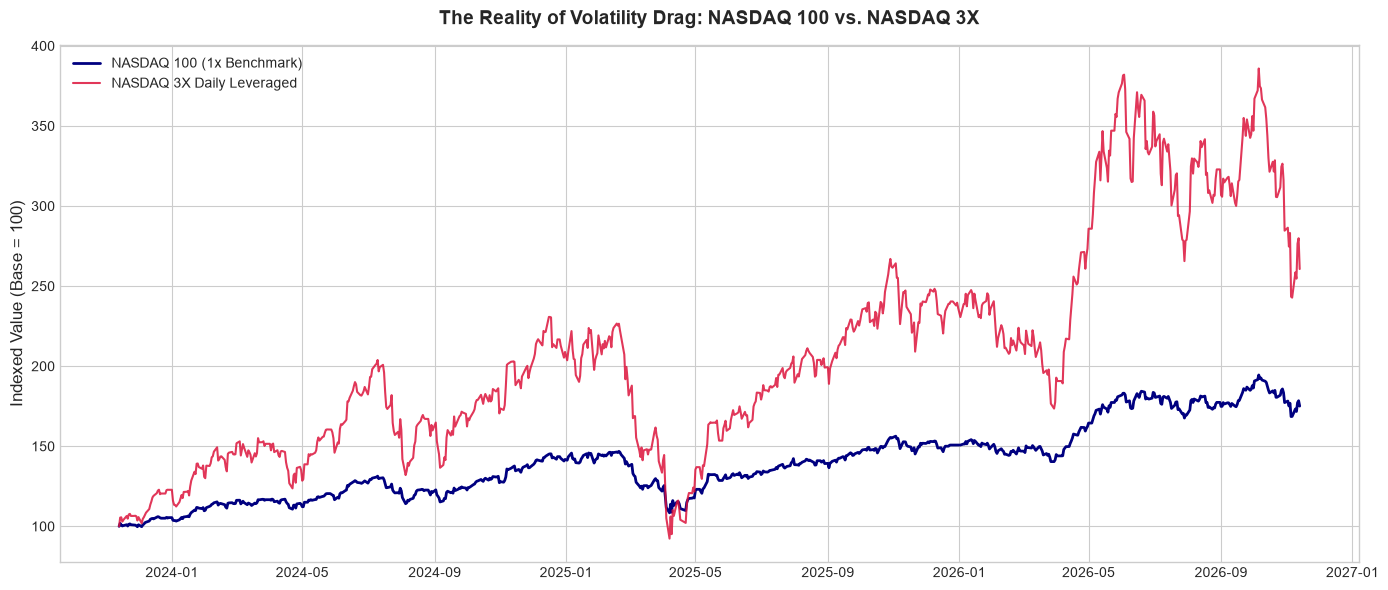

In [6]:
plt.figure(figsize=(14, 6))

norm_prices = prices / prices.iloc[0] * 100

plt.plot(norm_prices.index, norm_prices["NASDAQ"], label="NASDAQ 100 (1x Benchmark)", color="navy", linewidth=2)
plt.plot(norm_prices.index, norm_prices["NASDAQ 3X"], label="NASDAQ 3X Daily Leveraged", color="crimson", linewidth=1.5, alpha=0.85)

plt.title("The Reality of Volatility Drag: NASDAQ 100 vs. NASDAQ 3X", fontsize=14, fontweight="bold", pad=15)
plt.ylabel("Indexed Value (Base = 100)", fontsize=12)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 4. Human-in-the-Loop Decision Taxonomy

Rather than treating all 50 ETFs equally, we classify the universe into **4 functional decision buckets** specifically tailored for the 5 competition trading windows (Dec 7, 10, 14, 17, 21):

```
┌────────────────────────────────────────────────────────────────────────────────────────┐
│                      THE 4 HUMAN-IN-THE-LOOP DECISION BUCKETS                          │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ Bucket 1: CORE COMPOUNDING ANCHORS                                                     │
│ • Characteristics: Low/Medium Volatility (<18%), High Sharpe (>0.6), Broad Liquidity   │
│ • Role in Portfolio: Backbone allocations (40% - 60% of capital)                       │
│ • Key ETFs: WORLD, S&P 500, EUROPE 600, DIVIDEND LEADERS, STAPLES, HEALTH CARE         │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ Bucket 2: TACTICAL MOMENTUM DRIVERS                                                    │
│ • Characteristics: High Growth, Secular Tailwinds, Beta > 1.2 to Global Benchmark      │
│ • Role in Portfolio: Alpha capture when Technical Agent signals "Golden Trend"         │
│ • Key ETFs: SEMIS, CYBERSEC, BIOTECH, DEFENSE, INDIA, URANIUM                         │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ Bucket 3: CAPITAL PRESERVATION & NON-CORRELATED BUFFERS                                │
│ • Characteristics: Low/Negative equity correlation, Capital stability                 │
│ • Role in Portfolio: Hedging equity drawdowns & satisfying the >=5% cash buffer rule   │
│ • Key ETFs: OVERNIGHT CASH, US TREASURY 20Y, GLOBAL AGG BOND, GOLD                     │
├────────────────────────────────────────────────────────────────────────────────────────┤
│ Bucket 4: HIGH-BETA TACTICAL & HEDGING (STRICT LIMITS)                                 │
│ • Characteristics: Extreme Volatility (>40%), High Tail Risk, Daily Rebalancing        │
│ • Role in Portfolio: Max 1-window tactical bets (<5 days holding), Capped at <=8% each │
│ • Key ETFs: BITCOIN, CRYPTO EQUITY, NASDAQ 3X, EURO STOXX 2X, STOXX SHORT (-2x)       │
└────────────────────────────────────────────────────────────────────────────────────────┘
```


In [7]:
# Assign each ETF to one of the 4 decision buckets
def assign_decision_bucket(row):
    ticker = row["Ticker"]
    is_lev = row["Is Leveraged/Short"]
    vol = row["Annualized Volatility"]
    sharpe = row["Sharpe Ratio"]
    theme = row["Theme"]
    
    if is_lev or ticker in ["BITCOIN", "CRYPTO EQUITY"]:
        return "Bucket 4: High-Beta Tactical & Hedging (Capped <=8%)"
    elif theme in ["Money market (cash)", "Fixed income / Bonds"] or ticker == "GOLD":
        return "Bucket 3: Capital Preservation & Buffers"
    elif theme in ["Equity / Tech", "Frontier tech", "Emerging markets"] or ticker in ["URANIUM", "COPPER MINERS"]:
        return "Bucket 2: Tactical Momentum Drivers"
    else:
        return "Bucket 1: Core Compounding Anchors"

summary_table["Decision Bucket"] = summary_table.apply(assign_decision_bucket, axis=1)

# Summary of each bucket
bucket_stats = summary_table.groupby("Decision Bucket").agg(
    ETF_Count=("Ticker", "count"),
    Avg_Return=("Annualized Return", lambda x: (x.mean() * 100).round(1)),
    Avg_Volatility=("Annualized Volatility", lambda x: (x.mean() * 100).round(1)),
    Avg_Max_DD=("Max Drawdown", lambda x: (x.mean() * 100).round(1)),
    Avg_Sharpe=("Sharpe Ratio", lambda x: x.mean().round(2))
)
bucket_stats


,ETF_Count,Avg_Return,Avg_Volatility,Avg_Max_DD,Avg_Sharpe
Decision Bucket,,,,,
Bucket 1: Core Compounding Anchors,21,13.6,23.5,-27.2,0.71
Bucket 2: Tactical Momentum Drivers,15,20.0,28.1,-32.6,0.59
Bucket 3: Capital Preservation & Buffers,6,4.3,7.9,-10.3,-0.35
Bucket 4: High-Beta Tactical & Hedging (Capped <=8%),8,3.2,50.8,-57.9,-0.10


## 5. Summary for the Trading Windows

When the MAS generates order proposals during the 5 live trading dates, the human committee should apply this **Decision Matrix**:

| Market Regime (Macro Agent) | Technical Agent Signal | Recommended Bucket Allocation | Human Sign-Off Guideline |
| :--- | :--- | :--- | :--- |
| **Risk-On / Soft Landing** | Bullish ($> +0.4$) | 50% Bucket 1 + 35% Bucket 2 + 10% Cash + 5% Bucket 4 | Overweight **SEMIS, CYBERSEC, DEFENSE, S&P 500**. Allow 5% tactical in **NASDAQ 3X**. |
| **Choppy / Range-Bound** | Neutral ($-0.2$ to $+0.2$) | 60% Bucket 1 + 25% Bucket 3 + 15% Cash | Rotate into **DIVIDEND LEADERS, STAPLES, HEALTH CARE, OVERNIGHT CASH**. Zero leveraged exposure. |
| **Risk-Off / Geopolitical Shock** | Bearish ($< -0.3$) | 30% Bucket 1 + 40% Bucket 3 + 25% Cash + 5% Short | Overweight **OVERNIGHT CASH, GOLD, US TREASURY 20Y**. Deploy tactical hedge via **STOXX SHORT (-2x)**. |

